<xarray.Dataset>
Dimensions:   (lon: 321, lat: 161, month: 12)
Coordinates:
  * lon       (lon) float64 40.0 40.25 40.5 40.75 ... 119.2 119.5 119.8 120.0
  * lat       (lat) float64 -10.0 -9.75 -9.5 -9.25 ... 29.25 29.5 29.75 30.0
  * month     (month) int64 1 2 3 4 5 6 7 8 9 10 11 12
Data variables:
    so20chgt  (month, lat, lon) float32 ...
Attributes:
    CDI:          Climate Data Interface version 1.9.9rc1 (https://mpimet.mpg...
    Conventions:  CF-1.6
    history:      Wed Jun 26 17:06:13 2024: cdo remapbil,same_as_era5_grid 20...
    CDO:          Climate Data Operators version 1.9.9rc1 (https://mpimet.mpg...


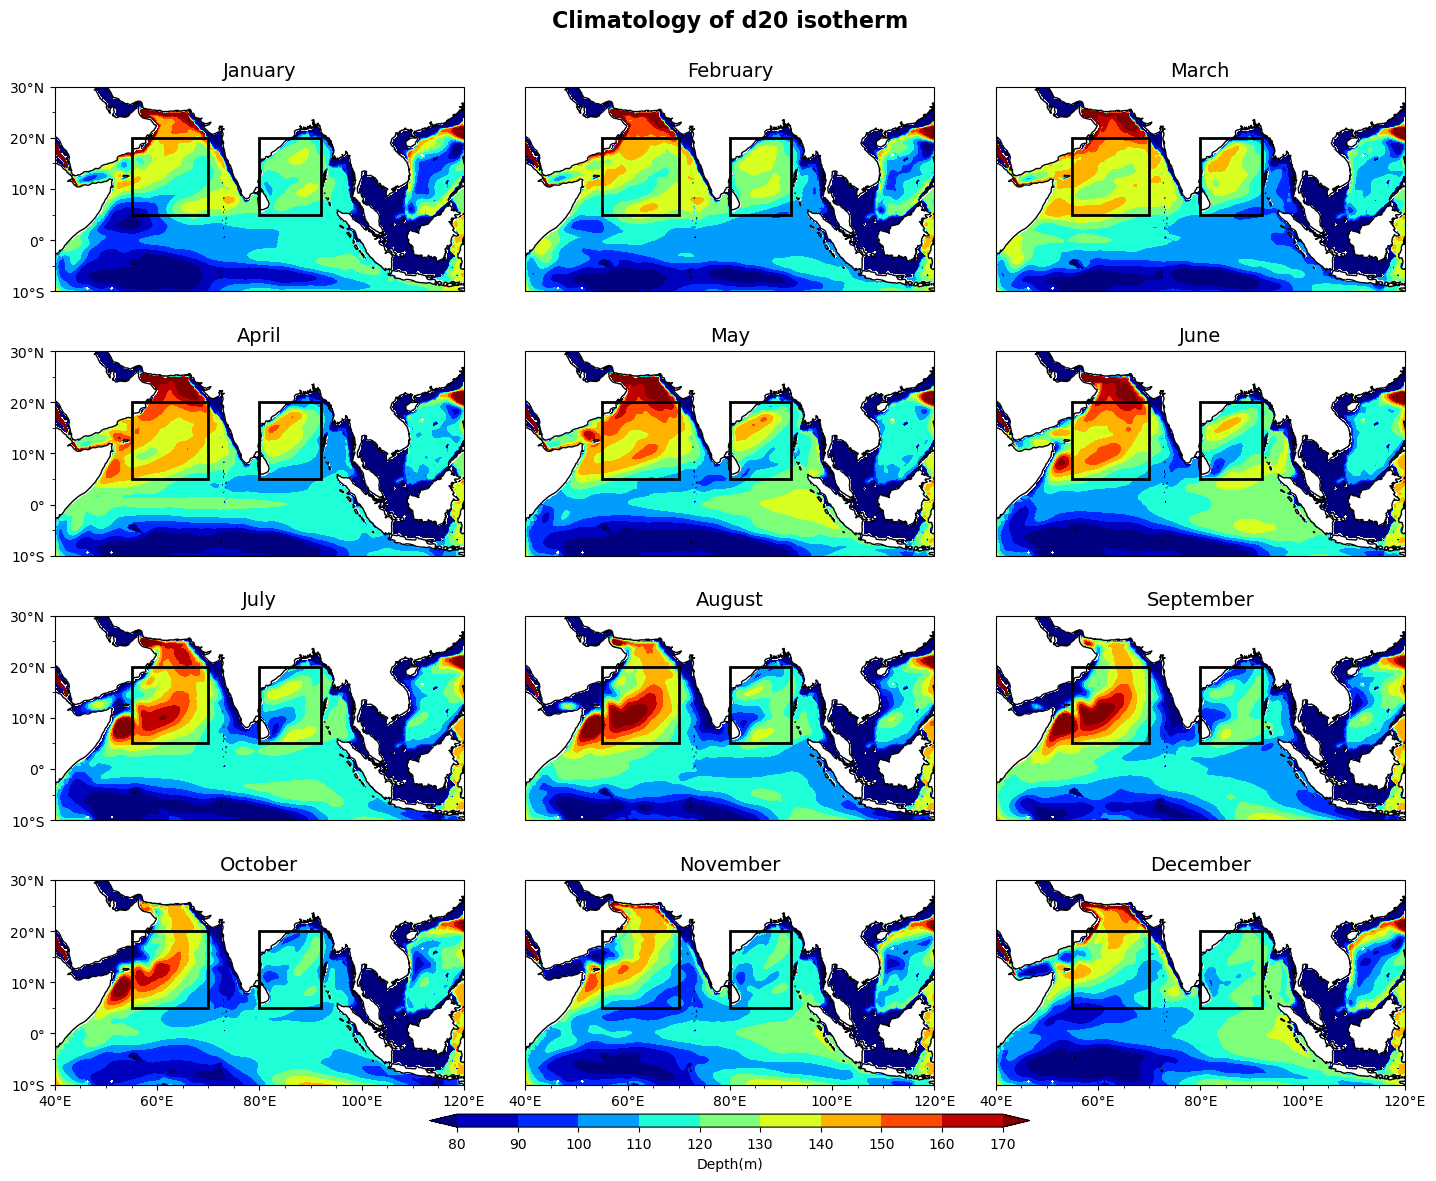

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import calendar
import cartopy.mpl.ticker as cticker
import calendar
from matplotlib.patches import Rectangle
from matplotlib.ticker import MultipleLocator
ds=xr.open_dataset('d20.nc')
print(ds)
Ild=ds['so20chgt'].values

clevels=np.arange(80,172,10)

fig,axs = plt.subplots(nrows = 4, ncols = 3, subplot_kw = {'projection':ccrs.PlateCarree()}, figsize = (15,13))
plt.subplots_adjust(left=0.05, right=0.95, bottom=0.113, top=0.9, wspace=0.15, hspace=0.15)
axs = axs.flatten()
for j in range(12):
    cf = axs[j].contourf(ds['lon'], ds['lat'],ds['so20chgt'][j],cmap='jet',extend='both',levels=clevels,transform=ccrs.PlateCarree())
    axs[j].coastlines()
    #axs[j].add_feature(cfeature.LAND,facecolor='0.7')
    # Define the xticks for longitude
    if j >= 9:
       lon_range = np.arange(np.floor(ds['lon'].min()), np.ceil(ds['lon'].max()) + 1, 20)
       axs[j].set_xticks(lon_range, crs=ccrs.PlateCarree())
       lon_formatter = cticker.LongitudeFormatter()
       axs[j].xaxis.set_major_formatter(lon_formatter)
       axs[j].xaxis.set_minor_locator(MultipleLocator(5))
    # Define the yticks for latitude
    if j%3==0:
       lat_range = np.arange(np.floor(ds['lat'].min()), np.ceil(ds['lat'].max()) + 1,10)
       axs[j].set_yticks(lat_range, crs=ccrs.PlateCarree())
       lat_formatter = cticker.LatitudeFormatter()
       axs[j].yaxis.set_major_formatter(lat_formatter)
       axs[j].yaxis.set_minor_locator(MultipleLocator(5))
    
    #add month name to the plot
    month_name=calendar.month_name[j+1]
    axs[j].text(0.5,1.05,month_name,ha='center',transform=axs[j].transAxes,fontsize=14)
plt.suptitle(('Climatology of d20 isotherm'),fontsize=16,fontweight='bold',y=0.95,)
box1=[55,70,5,20]
box2=[80,92,5,20]
for i in range(12):
    axs[i].add_patch(Rectangle((box1[0],box1[2]),box1[1]-box1[0],box1[3]-box1[2],fill=None,edgecolor='black',linewidth=2))
    axs[i].add_patch(Rectangle((box2[0],box2[2]),box2[1]-box2[0],box2[3]-box2[2],fill=None,edgecolor='black',linewidth=2))


# Define the subplot axis for the colorbar
cbar_ax = fig.add_axes([0.3, 0.09, 0.4, 0.01])
cbar = fig.colorbar(cf, cax=cbar_ax, orientation='horizontal', label='Depth(m)')
cbar.ax.xaxis.set_label_coords(0.5, -2.3)


plt.show()

In [42]:
ds['so20chgt'][0].min().values

array(0.)

In [9]:
ds['so20chgt'][0].max().values

array(1043.2244873)